In [1]:
from collections import defaultdict
import numpy as np
from dezerogym.gridworld import GridWorld


In [2]:
# utility functions (common functions)
def argmax(xs):
    idxes = [i for i, x in enumerate(xs) if x == max(xs)]
    if len(idxes) == 1:
        return idxes[0]
    elif len(idxes) == 0:
        return np.random.choice(len(xs))
    selected = np.random.choice(idxes)
    return selected

def greedy_probs(Q, state, epsilon=0, action_size=4):
    # 현재 상태에서 각 행동의 Q값을 가져옴
    qs = [Q[(state, action)] for action in range(action_size)]

    # Q값이 가장 큰 행동을 선택함 (동률이면 무작위 선택)
    max_action = argmax(qs)

    # 탐험을 위해 모든 행동에 동일한 확률을 먼저 할당
    base_prob = epsilon / action_size
    action_probs = {
        action: base_prob
        for action in range(action_size)
    }

    # 남은 확률을 가장 좋은 행동에 할당
    action_probs[max_action] += 1 - epsilon
    return action_probs

# TD Learning

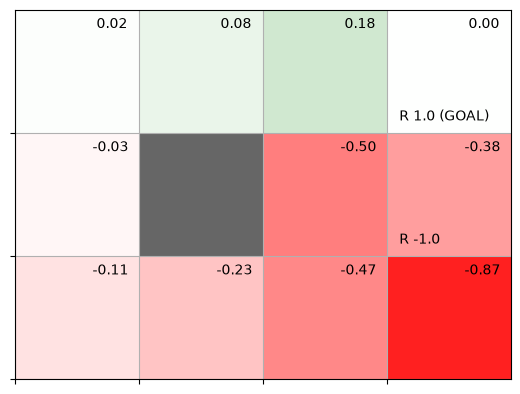

In [3]:
from collections import defaultdict
import numpy as np
from dezerogym.gridworld import GridWorld


class TdAgent:
    def __init__(self):
        self.gamma = 0.9
        self.alpha = 0.01
        self.action_size = 4

        random_actions = {0: 0.25, 1: 0.25, 2: 0.25, 3: 0.25}
        self.pi = defaultdict(lambda: random_actions)
        self.V = defaultdict(lambda: 0)

    def get_action(self, state):
        action_probs = self.pi[state]
        actions = list(action_probs.keys())
        probs = list(action_probs.values())
        return np.random.choice(actions, p=probs)

    def eval(self, state, reward, next_state, done):
        next_V = 0 if done else self.V[next_state]
        target = reward + self.gamma * next_V
        self.V[state] += (target - self.V[state]) * self.alpha


env = GridWorld()
agent = TdAgent()

episodes = 1000
for episode in range(episodes):
    state = env.reset()

    while True:
        action = agent.get_action(state)
        next_state, reward, done = env.step(action)

        agent.eval(state, reward, next_state, done)
        if done:
            break
        state = next_state

env.render_v(agent.V)

# SARSA 구현

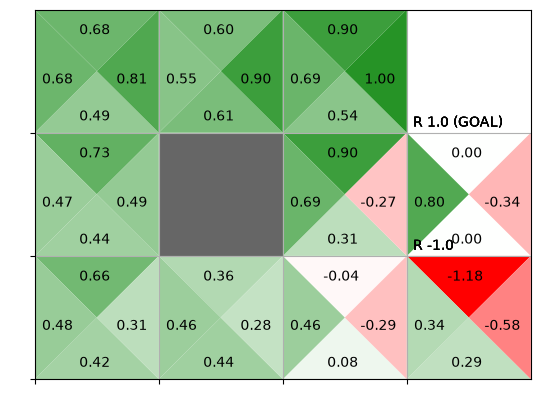

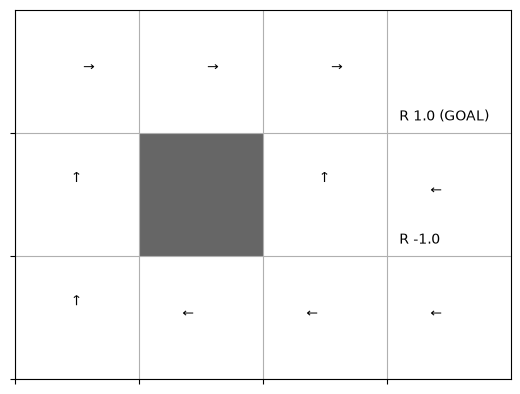

In [4]:
from collections import deque


class SarsaAgent:
    def __init__(self):
        self.gamma = 0.9        # 할인율
        self.alpha = 0.8         # 학습률
        self.epsilon = 0.1       # ε-greedy 정책의 탐험 비율
        self.action_size = 4     # 가능한 행동의 수

        # 처음 방문한 상태에서는 모든 행동을 같은 확률로 선택
        random_actions = {0: 0.25, 1: 0.25, 2: 0.25, 3: 0.25}
        self.pi = defaultdict(lambda: random_actions)
        self.Q = defaultdict(lambda: 0)  # 상태-행동 가치 함수
        self.memory = deque(maxlen=2)   # 연속한 두 경험을 저장

    def get_action(self, state):
        # 현재 상태의 정책에 따라 행동을 확률적으로 선택
        action_probs = self.pi[state]
        actions = list(action_probs.keys())
        probs = list(action_probs.values())
        return np.random.choice(actions, p=probs)

    def reset(self):
        # 에피소드가 시작될 때 이전 경험을 비움
        self.memory.clear()

    def update(self, state, action, reward, done):
        # 현재 경험을 저장하고, 다음 경험이 모일 때까지 대기
        self.memory.append((state, action, reward, done))
        if len(self.memory) < 2:
            return

        # 두 경험을 사용해 이전 상태-행동의 가치를 갱신
        state, action, reward, done = self.memory[0]
        next_state, next_action, _, _ = self.memory[1]
        next_q = 0 if done else self.Q[next_state, next_action]

        # SARSA 목표값: 보상 + 할인된 다음 행동 가치
        target = reward + self.gamma * next_q
        self.Q[state, action] += (target - self.Q[state, action]) * self.alpha

        # 갱신된 Q값으로 ε-greedy 정책을 업데이트
        self.pi[state] = greedy_probs(self.Q, state, self.epsilon)


env = GridWorld()
agent = SarsaAgent()

episodes = 10000
for episode in range(episodes):
    state = env.reset()
    agent.reset()

    while True:
        action = agent.get_action(state)
        next_state, reward, done = env.step(action)

        # 현재 경험을 기록하고, 이전 경험이 있으면 Q값을 갱신
        agent.update(state, action, reward, done)

        if done:
            # 마지막 상태의 경험까지 처리하기 위해 한 번 더 호출
            agent.update(next_state, None, None, None)
            break
        state = next_state

# 학습된 상태-행동 가치 함수 시각화
env.render_q(agent.Q)

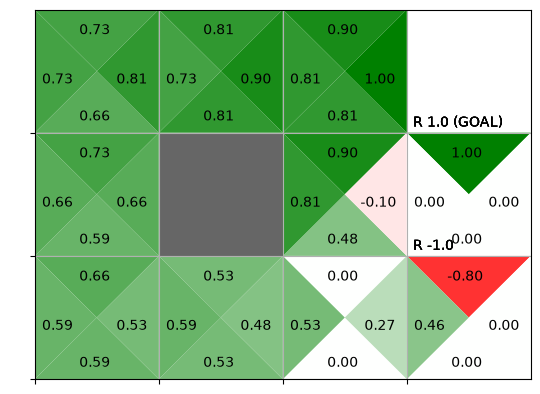

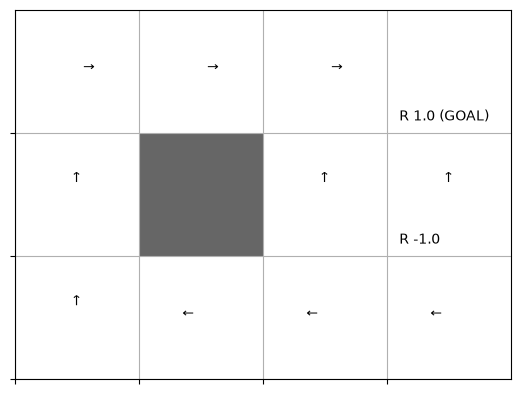

In [5]:
class QLearningAgent:
    def __init__(self):
        # 할인율과 학습률 설정
        self.gamma = 0.9
        self.alpha = 0.8
        self.epsilon = 0.1
        self.action_size = 4

        # 초기에는 모든 행동을 동일한 확률로 선택
        random_actions = {0: 0.25, 1: 0.25, 2: 0.25, 3: 0.25}

        # pi: 목표 정책, b: 행동 정책
        self.pi = defaultdict(lambda: random_actions)
        self.b = defaultdict(lambda: random_actions)

        # 상태-행동 가치 함수
        self.Q = defaultdict(lambda: 0)

    def get_action(self, state):
        # 행동 정책 b에 따라 행동 선택
        action_probs = self.b[state]
        actions = list(action_probs.keys())
        probs = list(action_probs.values())

        return np.random.choice(actions, p=probs)

    def update(self, state, action, reward, next_state, done):
        # 종료 상태에서는 다음 상태의 가치가 0
        if done:
            next_q_max = 0
        else:
            # 다음 상태에서 가장 큰 Q값을 선택
            next_qs = [
                self.Q[next_state, a]
                for a in range(self.action_size)
            ]
            next_q_max = max(next_qs)

        # Q-learning 목표값 계산
        target = reward + self.gamma * next_q_max

        # Q값 업데이트
        self.Q[state, action] += (target - self.Q[state, action]) * self.alpha

        # 목표 정책 pi를 탐욕 정책으로 업데이트
        self.pi[state] = greedy_probs(self.Q, state, epsilon=0)

        # 행동 정책 b를 ε-greedy 정책으로 업데이트
        self.b[state] = greedy_probs(self.Q, state, self.epsilon)


env = GridWorld()
agent = QLearningAgent()

# 에이전트 학습
episodes = 10000

for episode in range(episodes):
    state = env.reset()

    while True:
        # 현재 행동 정책에 따라 행동 선택
        action = agent.get_action(state)

        # 환경과 상호작용
        next_state, reward, done = env.step(action)

        # Q값 업데이트
        agent.update(
            state, action, reward, next_state, done
        )

        # 에피소드가 끝나면 종료
        if done:
            break

        state = next_state

# 학습된 Q값 시각화
env.render_q(agent.Q)